# Quantum-Secure Fraud Detection System
## Layer 2 — Classical, Post-Quantum, and Simulated Quantum-Secure Communication Research

This notebook does **not** begin as an isolated cryptography tutorial. It begins with Layer 1's real output and
follows it through the actual Layer 2 pipeline implemented in `src/security/`. Every table and figure below loads
a real artifact from `results/layer2/`, `results/integration/`, or `docs/research/layer2/` — nothing is
hand-typed from memory.

**BB84 in this project is a software SIMULATION.** No physical quantum channel, no hardware QKD deployment, and
no production key-distribution security claim is made anywhere in this notebook.

## 1. Layer 2 Objective

Given a transaction's fraud-risk assessment from Layer 1, select and apply an appropriate cryptographic security
profile, and empirically characterize the trade-off between how well that routing targets real fraud
(`docs/protocols/LAYER2_INTEGRATION_PROTOCOL.md`'s Fraud-Weighted Coverage) and its computational/communication
cost.

## 2. Overall QSFD Architecture

```mermaid
graph TD
    A[Transaction] --> B[Preprocessing]
    B --> C[Layer 1: classical + quantum research]
    C --> D[FraudAssessment]
    D --> E[SecurityContext]
    E --> F[SecurityPolicyEngine]
    F --> G[SecurityProfile]
    G --> H[Protected Transaction]
    H --> I[Audit]
```

![Overall QSFD architecture](../artifacts/figures/diagrams/overall_architecture.png)

## 3. Threat Model

Per the project's source SRS (`docs/project/PROJECT_REQUIREMENTS_TRACEABILITY.md`), Layer 2 addresses two
*different* threat classes:
- **Classical threats**: eavesdropping, tampering, forgery -- addressed by AES-256-GCM (confidentiality +
  integrity) and digital signatures (authenticity).
- **Future quantum threats**: Shor's algorithm breaking RSA/ECC, Grover's algorithm halving symmetric key
  strength -- addressed by migrating key establishment and signatures to standardized post-quantum algorithms.
  **Fraud risk and quantum-cryptographic threat are different risk dimensions** -- a low-fraud-risk transaction
  is not thereby "quantum-safe-exempt."

**Why Layer 2 exists as a separate research question**: fraud detection and cryptographic security address
different threats entirely. Layer 2 investigates *"how can transaction-risk intelligence interact with
quantum-safe security without conflating fraud risk and cryptographic threat?"*

![Refined architecture: fraud risk vs cryptographic risk](../artifacts/figures/diagrams/refined_fraud_vs_crypto_risk.png)

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if (Path.cwd() / "02_Layer2_Quantum_Secure_Cryptography_Research.ipynb").exists() else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

RESULTS_L2 = ROOT / "results" / "layer2"
RESULTS_INT = ROOT / "results" / "integration"

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
print(f"Repository root resolved to: {ROOT}")
assert (ROOT / "src" / "security").exists()

Repository root resolved to: D:\Quantum Secure Fraud Detection System


## 4-8. Layer 1 -> Layer 2 Contract, SecurityContext, SecurityPolicyEngine

The contract is `FraudAssessment` (`src/fraud_engine/schemas.py`, unchanged by any Layer 2 work) ->
`SecurityContext.from_fraud_assessment(...)` (`src/security/integration/schemas.py`). No Layer 2 code branches on
which model produced the assessment.

In [2]:
from src.fraud_engine.schemas import FraudAssessment
from src.security.integration.schemas import SecurityContext
from src.security.policy.security_selector import CategoricalPolicy, ContinuousPolicy, ALGORITHMS_BY_PROFILE

example = FraudAssessment(transaction_id="demo-1", fraud_probability=0.85, fraud_prediction=1,
                            risk_score=85.0, risk_level="HIGH", model_name="xgboost", model_version="v1",
                            threshold=0.581019)
ctx = SecurityContext.from_fraud_assessment(example)
decision = CategoricalPolicy().decide(ctx)
print("SecurityContext:", ctx.to_dict())
print("\nSecurityDecision:", decision.to_dict())

SecurityContext: {'transaction_id': 'demo-1', 'fraud_probability': 0.85, 'fraud_prediction': 1, 'risk_score': 85.0, 'risk_level': 'HIGH', 'model_name': 'xgboost', 'model_version': 'v1', 'threshold': 0.581019, 'top_contributing_features': [], 'transaction_sensitivity': 'standard', 'quantum_safe_mode': False, 'timestamp': '2026-09-30T13:03:36.970719+00:00'}

SecurityDecision: {'transaction_id': 'demo-1', 'profile': 'HYBRID_MAXIMUM', 'reason': 'categorical routing: risk_level=HIGH -> HYBRID_MAXIMUM', 'policy_version': 'adaptive_security_v1-categorical', 'layer1_inputs_used': {'risk_level': 'HIGH', 'transaction_sensitivity': 'standard'}, 'algorithms': {'key_establishment': 'ECDH-P256 + ML-KEM-768 (hybrid KDF)', 'symmetric': 'AES-256-GCM', 'signature': 'ML-DSA-65 + SLH-DSA-SHA2-128s (dual signature)'}, 'timestamp': '2026-09-30T13:03:36.970787+00:00'}


## 9. Baseline Security Principle

**Every profile, including BASELINE, uses full AES-256-GCM plus a real key-establishment algorithm.** Fraud risk
controls only *additional* protection layered on top -- never a weakened baseline. This is enforced in code and
tested (`tests/test_security_integration.py::test_categorical_policy_never_weakens_low_risk_below_baseline`).

In [3]:
for profile, algos in ALGORITHMS_BY_PROFILE.items():
    print(f"{profile:18s}: {algos}")

BASELINE          : {'key_establishment': 'ECDH-P256', 'symmetric': 'AES-256-GCM', 'signature': 'ECDSA-P256'}
PQC_ENHANCED      : {'key_establishment': 'ML-KEM-768', 'symmetric': 'AES-256-GCM', 'signature': 'ML-DSA-65'}
HYBRID_MAXIMUM    : {'key_establishment': 'ECDH-P256 + ML-KEM-768 (hybrid KDF)', 'symmetric': 'AES-256-GCM', 'signature': 'ML-DSA-65 + SLH-DSA-SHA2-128s (dual signature)'}
QKD_EXPERIMENTAL  : {'key_establishment': 'ECDH-P256 + ML-KEM-768 (hybrid KDF) + BB84-simulated key material', 'symmetric': 'AES-256-GCM', 'signature': 'ML-DSA-65 + SLH-DSA-SHA2-128s (dual signature)'}


## 10-14. Classical Cryptography and Post-Quantum Cryptography

### Standardization terminology mapping

| Project/proposal name | Current standard (used in code) |
|---|---|
| CRYSTALS-Kyber | **ML-KEM** (FIPS 203) |
| CRYSTALS-Dilithium | **ML-DSA** (FIPS 204) |
| SPHINCS+ | **SLH-DSA** (FIPS 205) |

These are the same algorithms under their standardized names, not different unrelated schemes.

### KEM (Key Encapsulation Mechanism)

$$(pk, sk) \leftarrow \text{KeyGen}() \qquad (c, K) \leftarrow \text{Encaps}(pk) \qquad K' \leftarrow \text{Decaps}(sk, c) \qquad K = K'$$

### Digital signature

$$\sigma \leftarrow \text{Sign}(sk, m) \qquad \text{Verify}(pk, m, \sigma) \in \{\text{true}, \text{false}\}$$

### AEAD (Authenticated Encryption with Associated Data) -- AES-256-GCM

$$(C, T) = \text{Enc}_K(N, P, A) \qquad P = \text{Dec}_K(N, C, T, A) \text{ or } \bot \text{ if } T \text{ invalid}$$

where $N$=nonce, $P$=plaintext, $A$=associated data, $T$=authentication tag. A single bit-flip in $C$ or $A$
causes decryption to fail closed ($\bot$), verified directly in `tests/test_security_classical.py`.

Implementations: `src/security/classical/{aes,rsa,ecc}.py` (the `cryptography` package) and
`src/security/pqc/{kem,signatures}.py` (pure-Python `kyber-py`/`dilithium-py`/`slh-dsa` -- liboqs's native
implementation could not be built in this sandbox; see `docs/research/layer2/LAYER2_REFERENCE_REPOSITORIES.md`).

In [4]:
classical_bench = pd.read_csv(RESULTS_L2 / "classical_crypto_benchmarks.csv")
kem_bench = pd.read_csv(RESULTS_L2 / "pqc_kem_benchmarks.csv")
sig_bench = pd.read_csv(RESULTS_L2 / "signature_benchmarks.csv")
kem_sizes = json.load(open(RESULTS_L2 / "pqc_kem_sizes.json"))
sig_sizes = json.load(open(RESULTS_L2 / "signature_sizes.json"))

print("PQC KEM sizes (bytes):", kem_sizes)
print("Signature sizes (bytes):", sig_sizes)

PQC KEM sizes (bytes): {'algorithm': 'ML-KEM-768', 'encapsulation_key_bytes': 1184, 'decapsulation_key_bytes': 2400, 'ciphertext_bytes': 1088}
Signature sizes (bytes): {'RSA-3072-PSS': 384, 'ECDSA-P256': 70, 'ML-DSA-65': 3309, 'SLH-DSA-SHA2-128s': 7856}


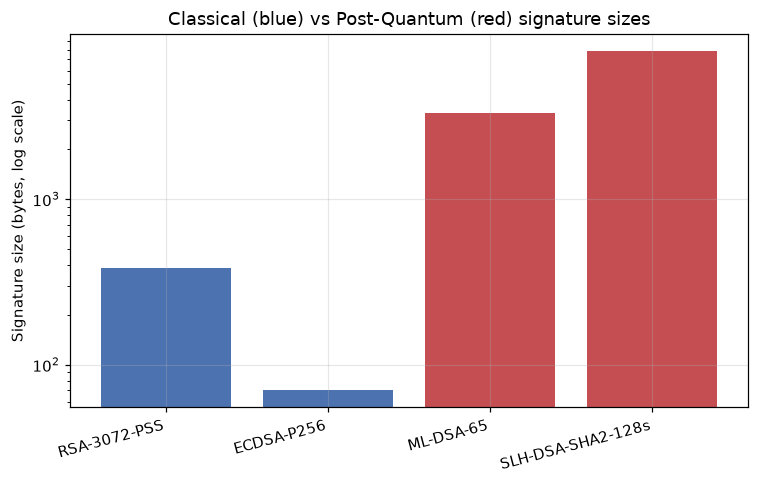

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
labels = list(sig_sizes.keys())
values = list(sig_sizes.values())
colors = ["#4C72B0", "#4C72B0", "#C44E52", "#C44E52"]
ax.bar(labels, values, color=colors)
ax.set_ylabel("Signature size (bytes, log scale)")
ax.set_yscale("log")
ax.set_title("Classical (blue) vs Post-Quantum (red) signature sizes")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "signature_sizes.png", bbox_inches="tight")
plt.show()

In [6]:
sig_bench_display = sig_bench[["algorithm", "operation", "mean_ms", "p95_ms", "p99_ms", "note"]] \
    if "note" in sig_bench.columns else sig_bench[["algorithm", "operation", "mean_ms", "p95_ms", "p99_ms"]]
sig_bench_display

,algorithm,operation,mean_ms,p95_ms,p99_ms,note
0,RSA-3072-PSS,sign,6.0351,8.0505,8.8269,NaN
1,RSA-3072-PSS,verify,0.2384,0.3967,0.4439,NaN
2,ECDSA-P256,sign,1.1513,0.1193,22.6668,NaN
3,ECDSA-P256,verify,0.2013,0.2603,0.2765,NaN
4,ML-DSA-65,sign,347.8604,864.0639,1348.6609,NaN
5,ML-DSA-65,verify,50.8330,71.3735,77.6228,NaN
6,SLH-DSA-SHA2-128s,sign,15238.1199,16268.8325,16343.8194,REDUCED_REPS_PURE_PYTHON
7,SLH-DSA-SHA2-128s,verify,13.1416,16.9207,18.4709,NaN


**ML-DSA-65's large sign-time variance** (mean 347.9ms, but ranging from 86ms to 1494ms across 30 runs) is a
**genuine mathematical property**, not measurement noise: Dilithium/ML-DSA uses Fiat-Shamir-with-aborts rejection
sampling, which by construction requires a variable, sometimes large, number of internal attempts before
producing a valid signature.

**SLH-DSA (SPHINCS+) signing took ~15 seconds per call** in this pure-Python implementation (reduced to 5
repetitions for that specific measurement, given the cost — `note: REDUCED_REPS_PURE_PYTHON` above). This
reflects both an inherent property of stateless hash-based signatures (building a large Merkle-tree
authentication structure per signature) and the overhead of a pure-Python (not native/hardware-accelerated)
implementation — this timing should **not** be generalized to an optimized native SLH-DSA implementation.

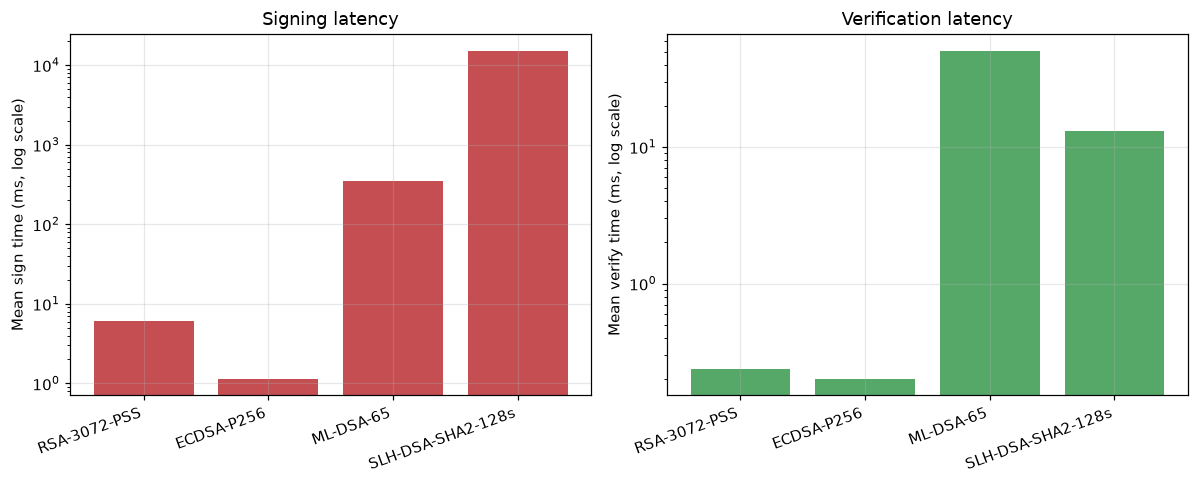

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sign_ops = sig_bench[sig_bench["operation"] == "sign"]
verify_ops = sig_bench[sig_bench["operation"] == "verify"]
axes[0].bar(sign_ops["algorithm"], sign_ops["mean_ms"], color="#C44E52")
axes[0].set_yscale("log"); axes[0].set_ylabel("Mean sign time (ms, log scale)")
axes[0].set_title("Signing latency"); plt.setp(axes[0].get_xticklabels(), rotation=20, ha="right")
axes[1].bar(verify_ops["algorithm"], verify_ops["mean_ms"], color="#55A868")
axes[1].set_yscale("log"); axes[1].set_ylabel("Mean verify time (ms, log scale)")
axes[1].set_title("Verification latency"); plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "sign_verify_latency.png", bbox_inches="tight")
plt.show()

## 20b. Cryptographic Protection Workflow

```mermaid
graph TD
    A[Transaction Payload] --> B[Security Profile Selection]
    B --> C[Key Establishment: ECDH and/or ML-KEM]
    C --> D[HKDF-SHA256 -> AES-256 key]
    D --> E[AES-256-GCM Authenticated Encryption]
    E --> F[Digital Signature: ECDSA / ML-DSA / plus SLH-DSA]
    F --> G[Protected Transaction]
    style C fill:#FCEAEA,stroke:#C44E52
```

![Layer 2 cryptographic workflow](../artifacts/figures/diagrams/layer2_crypto_workflow.png)

Note precisely: ML-KEM establishes a *key*, it does not directly encrypt the transaction payload -- AES-256-GCM
always performs the bulk symmetric encryption, per the implementation in `src/security/integration/secure_transaction.py`.

## 21. Hybrid Security Profile

The `HYBRID_MAXIMUM`/`QKD_EXPERIMENTAL` profiles combine a classical ECDH secret and a PQC ML-KEM secret via a
single HKDF-SHA256 call:

$$K = \text{HKDF-SHA256}(\text{ECDH-secret} \,\|\, \text{ML-KEM-secret}, \text{info})$$

This is a standard "concatenation combiner": security holds as long as **at least one** input secret is secure —
exactly the crypto-agility property a classical-to-PQC transition needs. `QKD_EXPERIMENTAL` additionally mixes in
BB84-simulated key material, but **always also** includes the classical+PQC hybrid secret, so a fraud-triggered
simulated-QKD step is never the *only* key material.

In [8]:
hybrid_bench = pd.read_csv(RESULTS_L2 / "hybrid_crypto_benchmarks.csv")
hybrid_bench

,algorithm,operation,n,mean_ms,median_ms,std_ms,p50_ms,p95_ms,p99_ms,min_ms,max_ms
0,ECDH-P256+ML-KEM-768,hybrid_key_establishment,30,19.8356,17.9186,6.1664,17.9186,33.4848,39.5743,14.5929,40.4249
1,ML-DSA-65+SLH-DSA-SHA2-128s,hybrid_dual_sign_ml_dsa_component_only,30,261.1112,193.6159,199.6151,193.6159,601.1205,931.1848,86.0900,1052.1905


## 24-29. Layer 1 -> Layer 2 Policy Ablation

Executed per the pre-specified `docs/protocols/LAYER2_INTEGRATION_PROTOCOL.md`. Definitions:

$$SER = \frac{N_{\text{escalated}}}{N_{\text{total}}} \qquad
FWC = \frac{N_{\text{fraud, escalated}}}{N_{\text{fraud, total}}} \qquad
BER = \frac{N_{\text{legitimate, escalated}}}{N_{\text{legitimate, total}}}$$

In [9]:
policy_ablation = pd.read_csv(RESULTS_INT / "policy_ablation.csv")
cols = [c for c in ["policy", "n", "n_fraud", "security_escalation_rate", "fraud_weighted_coverage",
                     "benign_escalation_rate"] if c in policy_ablation.columns]
policy_ablation[cols]

,policy,n,n_fraud,security_escalation_rate,fraud_weighted_coverage,benign_escalation_rate
0,A_categorical,55133,74,0.0011,0.7432,0.0001
1,B_continuous,55133,74,0.0011,0.7432,0.0001
2,C_anomaly_assisted,55133,74,0.0015,0.7432,0.0005


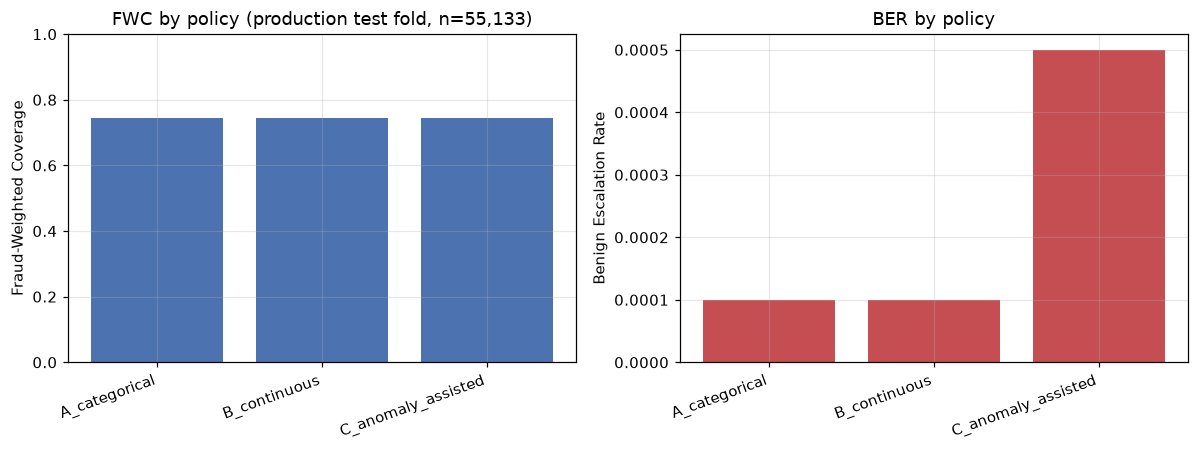

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(policy_ablation["policy"], policy_ablation["fraud_weighted_coverage"], color="#4C72B0")
axes[0].set_ylabel("Fraud-Weighted Coverage"); axes[0].set_ylim(0, 1)
axes[0].set_title("FWC by policy (production test fold, n=55,133)")
plt.setp(axes[0].get_xticklabels(), rotation=20, ha="right")
axes[1].bar(policy_ablation["policy"], policy_ablation["benign_escalation_rate"], color="#C44E52")
axes[1].set_ylabel("Benign Escalation Rate")
axes[1].set_title("BER by policy")
plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "policy_ablation.png", bbox_inches="tight")
plt.show()

**Finding**: Categorical (A) and Continuous (B) routing are behaviorally **identical** on this dataset's actual
fraud-probability distribution (74.32% coverage, both) -- an honest null result. **Anomaly-assisted routing (C)
adds no additional fraud coverage but a 5x higher benign escalation rate** -- a real negative finding for this
specific escalation rule at its tested threshold.

## 30. Quantum-Assisted Routing Experiment (Policy D)

Evaluated on its own separate sample (the locked QML-M CONFIRM_VAL subset, n=250) per the pre-specified protocol
— **never numerically merged** with the A/B/C table above (different sample size, prevalence, and feature
representation). Uses the frozen, already-validated Local-Sum-observable QNN (Notebook 1, Section 20-26) and
`classical_quantum_disagreement = |p_{\text{classical}} - p_{\text{quantum}}|`.

In [11]:
quantum_aux = json.load(open(RESULTS_INT / "quantum_auxiliary_result.json"))
print(json.dumps(quantum_aux, indent=2))

{
  "fwc_B": 0.9067,
  "fwc_D": 0.92,
  "ber_B": 0.0114,
  "ber_D": 0.1829,
  "delta_fwc": 0.0133,
  "delta_ber": 0.1714,
  "n_routing_changed": 31,
  "n_routing_changed_that_were_fraud": 1,
  "svm_rbf_pr_auc": 0.967,
  "local_sum_qnn_pr_auc": 0.8663,
  "mean_disagreement": 0.2809
}


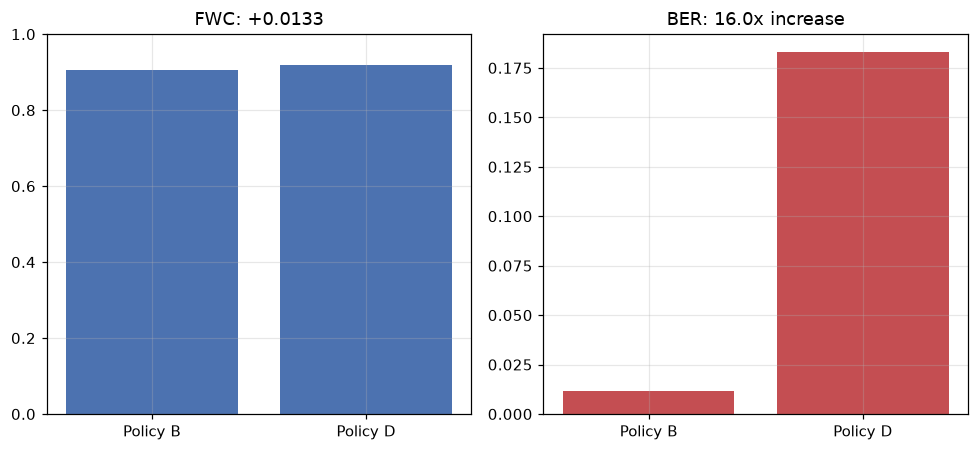


31 rows changed routing; only 1 of those were real fraud.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].bar(["Policy B", "Policy D"], [quantum_aux["fwc_B"], quantum_aux["fwc_D"]], color="#4C72B0")
axes[0].set_title(f"FWC: +{quantum_aux['delta_fwc']:.4f}"); axes[0].set_ylim(0, 1)
axes[1].bar(["Policy B", "Policy D"], [quantum_aux["ber_B"], quantum_aux["ber_D"]], color="#C44E52")
axes[1].set_title(f"BER: {quantum_aux['ber_D']/quantum_aux['ber_B']:.1f}x increase")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "quantum_auxiliary_routing.png", bbox_inches="tight")
plt.show()
print(f"\n{quantum_aux['n_routing_changed']} rows changed routing; only "
      f"{quantum_aux['n_routing_changed_that_were_fraud']} of those were real fraud.")

**QUANTUM AUXILIARY VALUE FOR LAYER 2: NOT SUPPORTED.** The classical/quantum disagreement signal increased
fraud coverage by only 1.33 percentage points (1 additional fraud caught out of 75) while increasing benign
escalation by **16x**, dramatically failing the protocol's pre-specified cost budget (BER within 1.5x of the
categorical baseline). This mirrors Layer 1's own finding that the Local-Sum QNN, despite being a real,
statistically validated architecture-level improvement over the Global-observable QNN, does not translate into
useful predictive information at the system level.

## 31-35. BB84 Theory, Simulation, and Results

Bases:

$$|0\rangle,\ |1\rangle \text{ (computational)} \qquad
|+\rangle = \frac{|0\rangle+|1\rangle}{\sqrt2},\ |-\rangle = \frac{|0\rangle-|1\rangle}{\sqrt2} \text{ (Hadamard)}$$

$$QBER = \frac{N_{\text{error}}}{N_{\text{sifted}}}$$

**This is a classical software simulation of BB84's information-theoretic structure** (`src/security/qkd/bb84.py`)
— no physical quantum channel, no hardware, no claim of physical QKD security.

```mermaid
graph TD
    A[Alice: random bits + random bases] --> B[State preparation]
    B --> C[Quantum channel - optional noise]
    C --> D[Bob: random bases, measures]
    D --> E[Public basis comparison]
    E --> F[Sifted key]
    F --> G[QBER estimate -> accept/reject]
    style G fill:#FCEAEA,stroke:#C44E52
```

![BB84 protocol](../artifacts/figures/diagrams/bb84_protocol_diagram.png)

**Intercept-resend eavesdropper**: Eve measures in a randomly chosen basis and resends a freshly prepared qubit.
When her basis does not match Alice's, her measurement (and resend) is uniformly random, introducing a
detectable bit error with probability approximately 25% on those qubits -- this is the mechanism the simulation
reproduces from real random measurements, not a hardcoded value.

![BB84 intercept-resend](../artifacts/figures/diagrams/bb84_intercept_resend_diagram.png)

In [13]:
bb84_summary = pd.read_csv(RESULTS_L2 / "bb84_summary.csv")
bb84_summary

,condition,n_trials,mean_qber,std_qber,mean_sifted_length,sifted_ratio,detection_rate,key_acceptance_rate
0,clean,30,0.0000,0.0000,1005.5,0.5027,NaN,1.0
1,noise_1pct,30,0.0089,0.0052,1005.5,0.5027,NaN,1.0
2,noise_5pct,30,0.0479,0.0091,1005.5,0.5027,NaN,1.0
3,noise_10pct,30,0.0947,0.0192,1005.5,0.5027,NaN,0.8
4,eve_intercept_resend,30,0.2394,0.0237,1004.0,0.5020,1.0,0.0
5,eve_and_noise_2pct,30,0.2642,0.0192,1004.0,0.5020,1.0,0.0


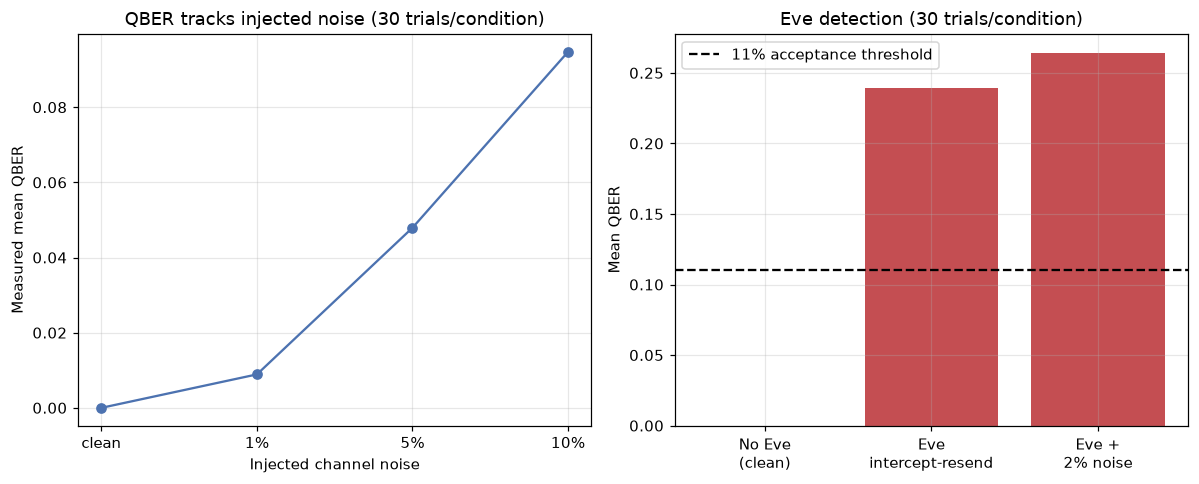

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
noise_order = ["clean", "noise_1pct", "noise_5pct", "noise_10pct"]
noise_conditions = bb84_summary.set_index("condition").loc[noise_order].reset_index()
axes[0].plot(["clean", "1%", "5%", "10%"], noise_conditions["mean_qber"], marker="o", color="#4C72B0")
axes[0].set_xlabel("Injected channel noise"); axes[0].set_ylabel("Measured mean QBER")
axes[0].set_title("QBER tracks injected noise (30 trials/condition)")

eve_conditions = bb84_summary[bb84_summary["condition"].str.contains("eve")]
labels = ["No Eve\n(clean)", "Eve\nintercept-resend", "Eve +\n2% noise"]
values = [bb84_summary[bb84_summary["condition"]=="clean"]["mean_qber"].iloc[0]] + list(eve_conditions["mean_qber"])
axes[1].bar(labels, values, color=["#55A868", "#C44E52", "#C44E52"])
axes[1].axhline(0.11, color="black", linestyle="--", label="11% acceptance threshold")
axes[1].set_ylabel("Mean QBER"); axes[1].set_title("Eve detection (30 trials/condition)")
axes[1].legend()
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "bb84_qber.png", bbox_inches="tight")
plt.show()

**Result, with exact experimental conditions stated** (30 trials per condition, raw key length 2000 bits,
`scripts/security/run_bb84_and_e2e_benchmarks.py`): QBER tracks injected channel noise almost linearly (1%->0.89%,
5%->4.79%, 10%->9.47%). The intercept-resend eavesdropper was detected in **30/30 trials** at these specific
settings (measured QBER ~24-26%, close to the textbook ~25% expectation for this attack) — this is not claimed as
a universal 100% detection guarantee, only as the observed rate under these exact conditions. At 10% channel
noise (near the 11% acceptance threshold), 20% of trials were rejected due to natural finite-sample QBER
estimation variance — an expected statistical effect, not a simulation defect.

## 35b. Implementation Backend as an Experimental Variable

Two follow-up experiments turn the implementation limitations above into explicit research questions rather than
leaving them as unquantified caveats: **(i)** does a native PQC backend change the measured cost picture, and
**(ii)** does an independent, circuit-level BB84 implementation reproduce the protocol-level simulator's results?

### (i) Native PQC backend attempt

`liboqs-python` (a wrapper around the native `liboqs` C library) was installed via `pip install liboqs-python`.
Importing it triggers an automatic native-library build via `cmake`, which failed immediately:

In [15]:
# Reproduces the exact failure observed when attempting the native PQC backend:
#   import oqs
#   -> FileNotFoundError: [WinError 2] The system cannot find the file specified
# because no CMake/MSVC C/C++ toolchain is present on PATH in this Windows environment.
import shutil
print("cmake on PATH:", shutil.which("cmake"))
print("cl.exe (MSVC) on PATH:", shutil.which("cl"))

cmake on PATH: None
cl.exe (MSVC) on PATH: None


**Result: NATIVE PQC BACKEND UNAVAILABLE IN CURRENT ENVIRONMENT.** No C/C++ toolchain (CMake, MSVC) is available
to build native `liboqs` in this sandboxed Windows environment, and no other cryptographic package was
substituted merely for having a similar name (per the pre-specified fallback rule for this experiment). This is a
disclosed environment limitation, not evidence about the algorithms themselves: the pure-Python reference
implementations used throughout this notebook remain correct (verified via genuine round-trip and
tamper-rejection tests) but their latency — including the ~15-second SLH-DSA signing time reported in Section 14
— should be read as **reference-implementation cost**, not as a general statement about SLH-DSA's practicality
on optimized native code. See `docs/research/layer2/LAYER2_LIMITATIONS.md` for the full record of this attempt.

### (ii) Qiskit circuit-level BB84 cross-validation

An independent, circuit-level BB84 implementation was built using Qiskit + Qiskit Aer
(`src/security/qkd/bb84_qiskit.py`), which prepares and measures explicit single-qubit states rather than
sampling protocol-level probabilities directly:

$$\text{bit=0, Z} \to |0\rangle \text{ (no gate)} \qquad \text{bit=1, Z} \to |1\rangle \text{ (X gate)}$$
$$\text{bit=0, X} \to |+\rangle \text{ (H gate)} \qquad \text{bit=1, X} \to |-\rangle \text{ (X then H)}$$

Measurement in the X basis applies an H gate before a computational-basis measurement.

In [16]:
from qiskit import QuantumCircuit
import sys
sys.path.insert(0, str(ROOT / "src"))
from security.qkd.bb84_qiskit import prepare_circuit, measure_circuit

fig = measure_circuit(prepare_circuit(1, "Z"), "Z").draw("mpl")
fig.suptitle("Representative Alice -> Bob circuit (bit=1, Z basis, matching bases)")
fig.savefig(ROOT / "artifacts" / "figures" / "layer2" / "bb84_circuit_full_representative.png", bbox_inches="tight")
plt.show()

In [17]:
fig = measure_circuit(prepare_circuit(1, "Z"), "X").draw("mpl")
fig.suptitle("Eve intercept: measures Alice's Z-basis |1> state in the wrong (X) basis")
fig.savefig(ROOT / "artifacts" / "figures" / "layer2" / "bb84_circuit_eve_intercept_representative.png", bbox_inches="tight")
plt.show()

The circuit implementation was run under the same six conditions as the protocol-level simulator (30 trials per
condition, `scripts/security/run_bb84_qiskit_benchmarks.py`), using a reduced raw-bit count per trial (200 vs.
2000) to bound per-qubit circuit-simulation overhead -- this reduction is disclosed, not hidden.

In [18]:
bb84_cross = pd.read_csv(RESULTS_L2 / "bb84_cross_implementation_comparison.csv")
bb84_cross

,condition,protocol_mean_qber,qiskit_mean_qber,abs_diff,protocol_detection_rate,qiskit_detection_rate
0,clean,0.0000,0.0000,0.0000,NaN,NaN
1,noise_1pct,0.0089,0.0134,0.0045,NaN,NaN
2,noise_5pct,0.0479,0.0503,0.0024,NaN,NaN
3,noise_10pct,0.0947,0.1009,0.0062,NaN,NaN
4,eve_intercept_resend,0.2394,0.2447,0.0053,1.0,1.0
5,eve_and_noise_2pct,0.2642,0.2647,0.0005,1.0,1.0


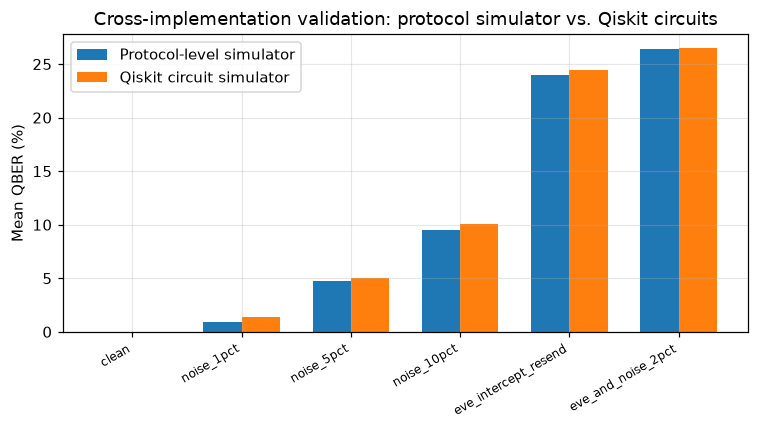

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(bb84_cross))
width = 0.35
ax.bar([i - width/2 for i in x], bb84_cross["protocol_mean_qber"].astype(float) * 100, width, label="Protocol-level simulator")
ax.bar([i + width/2 for i in x], bb84_cross["qiskit_mean_qber"].astype(float) * 100, width, label="Qiskit circuit simulator")
ax.set_xticks(list(x)); ax.set_xticklabels(bb84_cross["condition"], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("Mean QBER (%)")
ax.set_title("Cross-implementation validation: protocol simulator vs. Qiskit circuits")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "bb84_cross_implementation_comparison.png", bbox_inches="tight")
plt.show()

**Result: the two independent implementations agree closely** across all six conditions (largest absolute
difference 0.0062, on 200-bit vs. 2000-bit samples per trial) -- see the table above. The Qiskit circuit
implementation also detected the intercept-resend eavesdropper in 30/30 trials at the same 0.11 QBER threshold.
This is cross-implementation validation that the protocol-level simulator's sifting and QBER-estimation logic
correctly reproduces the behavior of explicit per-qubit state preparation and measurement circuits.

**This does not change the software-simulation status of BB84 in this project.** Running these circuits on
Qiskit Aer's classical simulator (or, hypothetically, on real IBM Quantum hardware) still transmits no physical
photon and exercises no physical no-cloning property. **BB84 in this project remains, in every implementation, a
software simulation** -- the improvement is circuit-level validation, not physical quantum key distribution.

## 36-37. End-to-End Secure Transaction Pipeline and Latency

In [20]:
e2e = pd.read_csv(RESULTS_L2 / "end_to_end_benchmarks.csv")
cols = [c for c in ["case", "fraud_probability", "selected_profile", "total_security_ms"] if c in e2e.columns]
e2e[cols]

,case,fraud_probability,selected_profile,total_security_ms
0,very_low_risk,0.02,BASELINE,23.9150
1,borderline_low_medium,0.29,BASELINE,1.2597
2,medium_risk,0.50,PQC_ENHANCED,52.6575
3,borderline_medium_high,0.69,PQC_ENHANCED,45.3424
4,high_risk,0.90,HYBRID_MAXIMUM,6306.7178


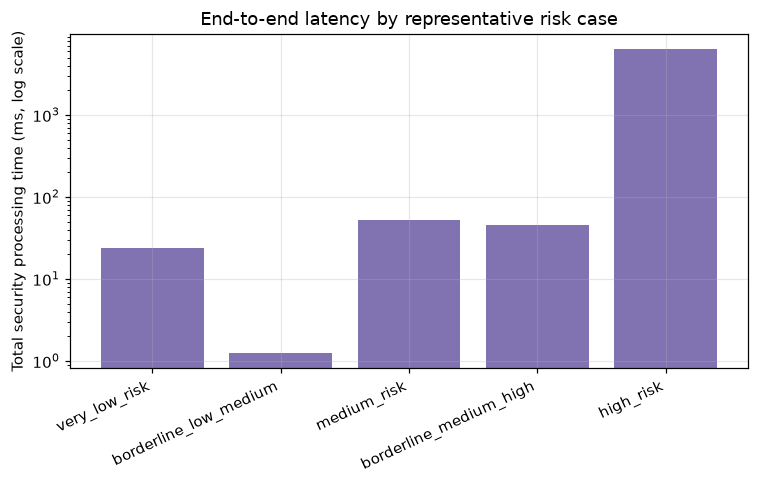


BASELINE/PQC_ENHANCED add tens of ms (plausible for real-time processing).
HYBRID_MAXIMUM adds seconds, dominated by SLH-DSA signing -- a real, disclosed limitation
of this pure-Python implementation, not minimized here or in docs/research/layer2/LAYER2_RESULTS.md.


In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(e2e["case"], e2e["total_security_ms"], color="#8172B2")
ax.set_yscale("log")
ax.set_ylabel("Total security processing time (ms, log scale)")
ax.set_title("End-to-end latency by representative risk case")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer2" / "end_to_end_latency.png", bbox_inches="tight")
plt.show()
print("\nBASELINE/PQC_ENHANCED add tens of ms (plausible for real-time processing).")
print("HYBRID_MAXIMUM adds seconds, dominated by SLH-DSA signing -- a real, disclosed limitation")
print("of this pure-Python implementation, not minimized here or in docs/research/layer2/LAYER2_RESULTS.md.")

## 38. Negative Results (Consolidated)

| Finding | Section |
|---|---|
| Categorical vs continuous routing: no difference on this dataset | 24-29 |
| Anomaly-assisted routing adds cost without adding fraud coverage | 24-29 |
| Quantum-assisted routing fails its own pre-specified cost budget by 16x | 30 |
| HYBRID_MAXIMUM/QKD_EXPERIMENTAL cost ~4-6+ seconds, dominated by SLH-DSA | 21, 36-37 |
| SLH-DSA is not currently practical in a real-time path (pure-Python) | 14 |
| Native `liboqs` PQC backend unavailable in this environment (no C/CMake toolchain) | 35b |

## 39. Scientific Contribution

A working implementation and empirical benchmark of classical (AES-256-GCM, RSA-3072, ECC/P-256), standardized
post-quantum (ML-KEM-768, ML-DSA-65, SLH-DSA-SHA2-128s), and simulated-QKD-oriented (BB84) security components,
integrated into a risk-adaptive pipeline driven by real Layer 1 fraud intelligence via a model-agnostic contract.
The integration experiment provides a **quantified, reproducible answer** (not an assumed one) to whether
richer Layer 1 signals improve Layer 2 routing: for anomaly and quantum-auxiliary signals specifically, on this
data, they do not clear a pre-specified cost bar.

## 40. Limitations

See `docs/research/layer2/LAYER2_LIMITATIONS.md` and
`docs/research/integration/LAYER1_LAYER2_INTEGRATION_EXPERIMENT_RESULTS.md` for the full itemized lists —
summarized: pure-Python PQC performance is not production-representative and a native `liboqs` backend could not
be installed in this environment (no C/CMake toolchain); no concurrency/load testing exists; the policy
ablation's null result for categorical-vs-continuous may be dataset-specific; Policy D's sample is small (n=250);
the Qiskit BB84 cross-validation used a reduced per-trial bit count (200 vs. 2000) to bound simulator overhead.

## 41. Layer 2 Conclusion

Classical, post-quantum, and simulated-QKD security components are implemented, tested, and benchmarked. The
risk-adaptive integration with Layer 1 works end-to-end and is auditable. Of the two "richer signal" hypotheses
tested (anomaly-assisted and quantum-assisted routing), **neither is supported by the evidence** at their tested
configurations — both add cost without a correspondingly defensible fraud-coverage gain. Categorical and
continuous routing are equally effective on this dataset. No claim of quantum advantage, quantum supremacy, or
physical QKD security is made.

### What Layer 2 Establishes / Does Not Establish

| Establishes | Does Not Establish |
|---|---|
| Classical + standardized PQC (ML-KEM/ML-DSA/SLH-DSA) can be integrated into a common transaction-security architecture | Universal PQC algorithm performance (pure-Python only) |
| BB84 simulator reproduces expected eavesdropping/noise behavior under stated conditions (30/30 detection) | Physical QKD security or hardware quantum communication |
| An independent Qiskit circuit implementation cross-validates the protocol-level BB84 simulator (agreement within 0.62 pp across 6 conditions) | That circuit-level simulation is physical QKD -- it is not |
| Fraud risk and cryptographic-quantum-threat posture must be modeled as separate axes | Risk-adaptive security is universally ineffective (only tested configurations failed their cost budget) |
| Real, repeated-measurement cryptographic benchmarks characterize genuine PQC migration cost | That this cost is representative of optimized/native PQC implementations (native `liboqs` backend attempted, unavailable in this environment) |

## 42. Layer 3 — Future Work

Explicitly not implemented in this project: MITM, replay, brute-force, and adversarial ML (evasion/poisoning)
attack simulations; Shor's and Grover's algorithm demonstrations against production-scale keys (Shor threatens
RSA/ECC asymptotically; Grover halves effective symmetric-key search strength — neither is demonstrated against
real production key sizes in this project, nor should such a claim ever be made without a genuine experiment);
QKD-specific attack extensions beyond intercept-resend; formal cryptographic migration-risk analysis. These
remain future work, deliberately deferred so Layers 1 and 2 could be completed to a defensible standard first.

---
*Generated by `scripts/notebooks/build_notebook_2.py`, executed by `scripts/notebooks/execute_notebooks.py`.*